
# Evaluare 01: Învățarea supervizată
Acest test are scopul de a evalua cunoștințele tale despre importul datelor, vizualizarea acestora și utilizarea modelelor de machine learning.
Te rugăm să completezi cerințele direct în celulele dedicate fiecărei secțiuni.


**Soluție completată.** Arhiva furnizată conține datele originale UCI HAR, nu CSV-ul menționat în enunț. Prima celulă generează CSV-ul din arhivă. Regresia prezice o măsurătoare numerică; clasificarea prezice activitatea. Sunt incluse și exercițiile opționale. Biblioteci: pandas, numpy, matplotlib, seaborn, scikit-learn. Rulați celulele în ordine.

## 1. Importul datelor
1. Importă biblioteca `pandas` și încarcă fișierul `Human_Activity_Recognition_Using_Smartphones_Data.csv`.
2. Verifică dimensiunile și tipurile de date.
3. Afișează primele 5 rânduri din DataFrame și verifică prezența valorilor lipsă.


In [1]:
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style='whitegrid')
SEED = 42
csv_path = Path('Human_Activity_Recognition_Using_Smartphones_Data.csv')
# Arhiva primită conține încă o arhivă, cu fișierele originale UCI HAR.
# Conversia este locală și nu necesită acces la internet.
if not csv_path.exists():
    candidates = [Path('human+activity+recognition+using+smartphones.zip'),
                  Path.home() / 'Downloads' / 'human+activity+recognition+using+smartphones.zip']
    archive = next((p for p in candidates if p.exists()), None)
    if archive is None:
        raise FileNotFoundError('Pune arhiva ZIP sau CSV-ul lângă notebook.')
    with ZipFile(archive) as outer:
        with ZipFile(BytesIO(outer.read('UCI HAR Dataset.zip'))) as z:
            prefix = 'UCI HAR Dataset/'
            names = pd.read_csv(z.open(prefix+'features.txt'), sep=r'\s+', header=None)[1]
            # Unele nume originale se repetă; indicele asigură nume unice.
            columns = [f'{i+1:03d}_{name}' for i, name in enumerate(names)]
            labels = pd.read_csv(z.open(prefix+'activity_labels.txt'), sep=r'\s+', header=None)
            mapping = dict(zip(labels[0], labels[1]))
            frames = []
            for part in ['train', 'test']:
                frame = pd.read_csv(z.open(prefix+f'{part}/X_{part}.txt'), sep=r'\s+', header=None)
                frame.columns = columns
                y = pd.read_csv(z.open(prefix+f'{part}/y_{part}.txt'), header=None)[0]
                frame['Activity'] = y.map(mapping)
                frame['Subject'] = pd.read_csv(z.open(prefix+f'{part}/subject_{part}.txt'), header=None)[0]
                frames.append(frame)
            pd.concat(frames, ignore_index=True).to_csv(csv_path, index=False)

df = pd.read_csv(csv_path)
print('Dimensiuni (rânduri, coloane):', df.shape)
print('Tipuri de date:'); display(df.dtypes.to_frame('tip'))
display(df.head())
missing = df.isna().sum()
print('Valori lipsă în total:', missing.sum())
display(missing[missing > 0].to_frame('valori_lipsă'))
print('Distribuția activităților:'); display(df['Activity'].value_counts())
feature_cols = [c for c in df.select_dtypes(include='number').columns if c != 'Subject']
# Subject este identificator de persoană, nu caracteristică predictivă.


,tip
001_tBodyAcc-mean()-X,float64
002_tBodyAcc-mean()-Y,float64
003_tBodyAcc-mean()-Z,float64
004_tBodyAcc-std()-X,float64
005_tBodyAcc-std()-Y,float64
...,...
"559_angle(X,gravityMean)",float64
"560_angle(Y,gravityMean)",float64
"561_angle(Z,gravityMean)",float64
Activity,str


,001_tBodyAcc-mean()-X,002_tBodyAcc-mean()-Y,003_tBodyAcc-mean()-Z,004_tBodyAcc-std()-X,005_tBodyAcc-std()-Y,006_tBodyAcc-std()-Z,007_tBodyAcc-mad()-X,008_tBodyAcc-mad()-Y,009_tBodyAcc-mad()-Z,010_tBodyAcc-max()-X,011_tBodyAcc-max()-Y,012_tBodyAcc-max()-Z,013_tBodyAcc-min()-X,014_tBodyAcc-min()-Y,015_tBodyAcc-min()-Z,016_tBodyAcc-sma(),017_tBodyAcc-energy()-X,018_tBodyAcc-energy()-Y,019_tBodyAcc-energy()-Z,020_tBodyAcc-iqr()-X,021_tBodyAcc-iqr()-Y,022_tBodyAcc-iqr()-Z,023_tBodyAcc-entropy()-X,024_tBodyAcc-entropy()-Y,025_tBodyAcc-entropy()-Z,"026_tBodyAcc-arCoeff()-X,1","027_tBodyAcc-arCoeff()-X,2","028_tBodyAcc-arCoeff()-X,3","029_tBodyAcc-arCoeff()-X,4","030_tBodyAcc-arCoeff()-Y,1","031_tBodyAcc-arCoeff()-Y,2","032_tBodyAcc-arCoeff()-Y,3","033_tBodyAcc-arCoeff()-Y,4","034_tBodyAcc-arCoeff()-Z,1","035_tBodyAcc-arCoeff()-Z,2","036_tBodyAcc-arCoeff()-Z,3","037_tBodyAcc-arCoeff()-Z,4","038_tBodyAcc-correlation()-X,Y","039_tBodyAcc-correlation()-X,Z","040_tBodyAcc-correlation()-Y,Z",...,524_fBodyBodyAccJerkMag-entropy(),525_fBodyBodyAccJerkMag-maxInds,526_fBodyBodyAccJerkMag-meanFreq(),527_fBodyBodyAccJerkMag-skewness(),528_fBodyBodyAccJerkMag-kurtosis(),529_fBodyBodyGyroMag-mean(),530_fBodyBodyGyroMag-std(),531_fBodyBodyGyroMag-mad(),532_fBodyBodyGyroMag-max(),533_fBodyBodyGyroMag-min(),534_fBodyBodyGyroMag-sma(),535_fBodyBodyGyroMag-energy(),536_fBodyBodyGyroMag-iqr(),537_fBodyBodyGyroMag-entropy(),538_fBodyBodyGyroMag-maxInds,539_fBodyBodyGyroMag-meanFreq(),540_fBodyBodyGyroMag-skewness(),541_fBodyBodyGyroMag-kurtosis(),542_fBodyBodyGyroJerkMag-mean(),543_fBodyBodyGyroJerkMag-std(),544_fBodyBodyGyroJerkMag-mad(),545_fBodyBodyGyroJerkMag-max(),546_fBodyBodyGyroJerkMag-min(),547_fBodyBodyGyroJerkMag-sma(),548_fBodyBodyGyroJerkMag-energy(),549_fBodyBodyGyroJerkMag-iqr(),550_fBodyBodyGyroJerkMag-entropy(),551_fBodyBodyGyroJerkMag-maxInds,552_fBodyBodyGyroJerkMag-meanFreq(),553_fBodyBodyGyroJerkMag-skewness(),554_fBodyBodyGyroJerkMag-kurtosis(),"555_angle(tBodyAccMean,gravity)","556_angle(tBodyAccJerkMean),gravityMean)","557_angle(tBodyGyroMean,gravityMean)","558_angle(tBodyGyroJerkMean,gravityMean)","559_angle(X,gravityMean)","560_angle(Y,gravityMean)","561_angle(Z,gravityMean)",Activity,Subject
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,-0.567378,-0.744413,0.852947,0.685845,0.814263,-0.965523,-0.999945,-0.999863,-0.994612,-0.994231,-0.987614,-0.943220,-0.407747,-0.679338,-0.602122,0.929294,-0.853011,0.359910,-0.058526,0.256892,-0.224848,0.264106,-0.095246,0.278851,-0.465085,0.491936,-0.190884,0.376314,0.435129,0.660790,...,-1.0,-0.936508,0.346989,-0.516080,-0.802760,-0.980135,-0.961309,-0.973653,-0.952264,-0.989498,-0.980135,-0.999240,-0.992656,-0.701291,-1.000000,-0.128989,0.586156,0.374605,-0.991990,-0.990697,-0.989941,-0.992448,-0.991048,-0.991990,-0.999937,-0.990458,-0.871306,-1.000000,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING,1
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,-0.557851,-0.818409,0.849308,0.685845,0.822637,-0.981930,-0.999991,-0.999788,-0.998405,-0.999150,-0.977866,-0.948225,-0.714892,-0.500930,-0.570979,0.611627,-0.329549,0.284213,0.284595,0.115705,-0.090963,0.294310,-0.281211,0.085988,-0.022153,-0.016657,-0.220643,-0.013429,-0.072692,0.579382,...,-1.0,-0.841270,0.532061,-0.624871,-0.900160,-0.988296,-0.983322,-0.982659,-0.986321,-0.991829,-0.988296,-0.999811,-0.993979,-0.720683,-0.948718,-0.271958,-0.336310,-0.720015,-0.995854,-0.996399,-0.995442,-0.996866,-0.994440,-0.995854,-0.999981,-0.994544,-1.000000,-1.000000,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING,1
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,-0.557851,-0.818409,0.843609,0.682401,0.839344,-0.983478,-0.999969,-0.999660,-0.999470,-0.997130,-0.964810,-0.974675,-

,valori_lipsă


Activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64

Dimensiuni (rânduri, coloane): (10299, 563)
Tipuri de date:
Valori lipsă în total: 0
Distribuția activităților:



## 2. Vizualizare date cu Matplotlib și Seaborn
1. Creează un grafic scatter care să afișeze relația dintre două coloane numeric.
2. Utilizează Seaborn pentru a crea o hartă de căldură (heatmap) a corelațiilor dintre coloane.


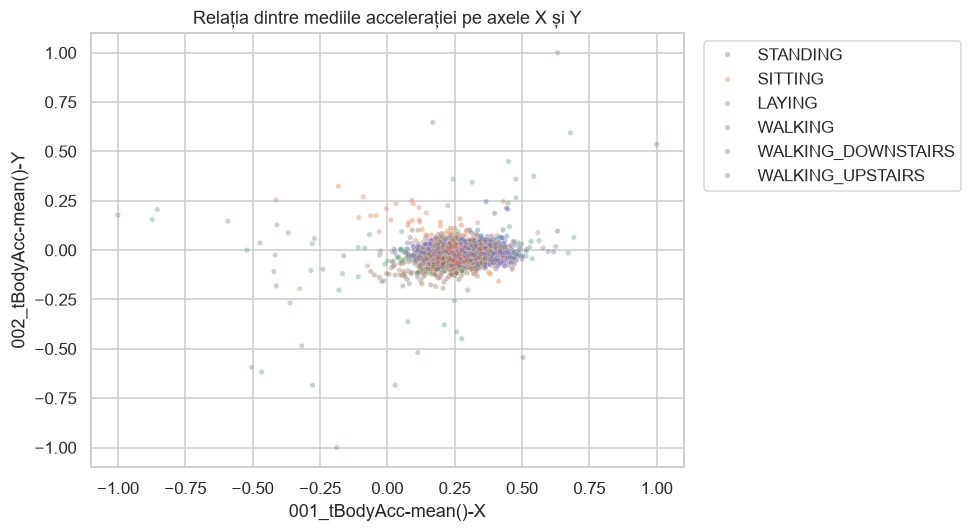

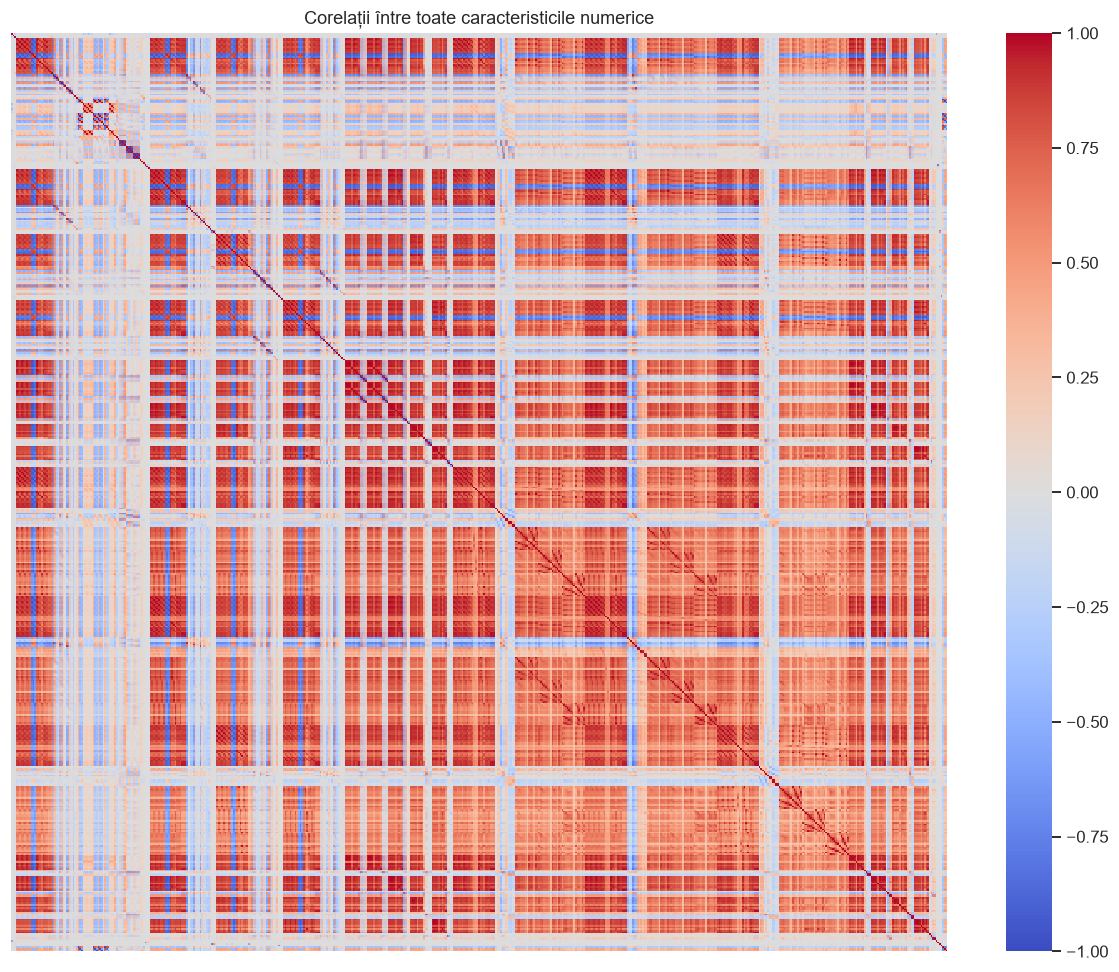

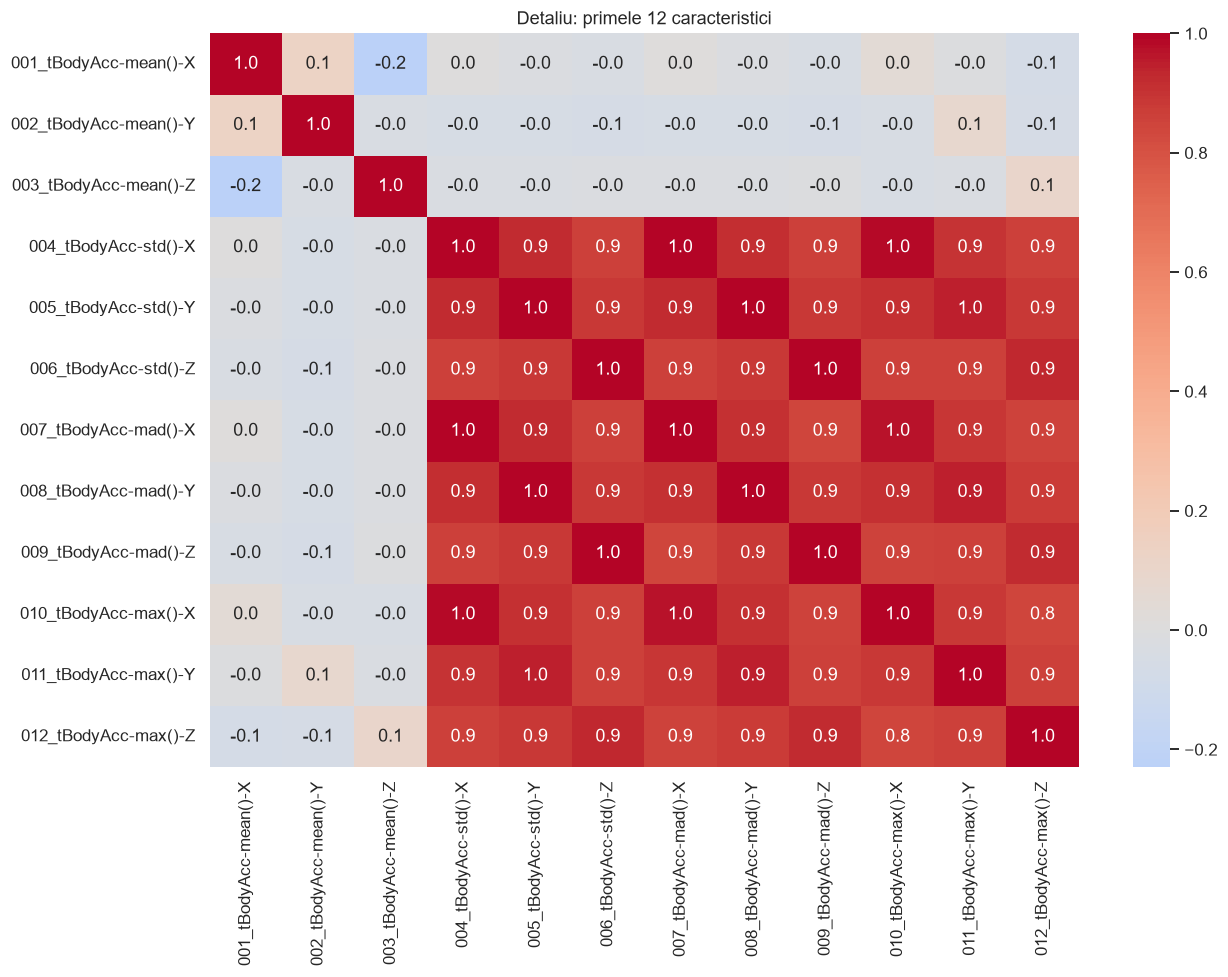

In [2]:
x_col, y_col = feature_cols[0], feature_cols[1]
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x=x_col, y=y_col, hue='Activity', s=12, alpha=.4)
plt.title('Relația dintre mediile accelerației pe axele X și Y')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left'); plt.tight_layout(); plt.show()
# Matricea completă include toate cele 561 de caracteristici numerice.
corr = df[feature_cols].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            xticklabels=False, yticklabels=False)
plt.title('Corelații între toate caracteristicile numerice'); plt.tight_layout(); plt.show()
# Detaliu lizibil pentru primele 12 caracteristici.
plt.figure(figsize=(12, 9))
sns.heatmap(corr.iloc[:12, :12], cmap='coolwarm', center=0, annot=True, fmt='.1f')
plt.title('Detaliu: primele 12 caracteristici'); plt.tight_layout(); plt.show()


## 3. Metrici ale erorii
1. Împarte setul de date în seturi de antrenare și testare (80%-20%).
2. Construiește un model de regresie liniară pe datele numerice.
3. Evaluează performanța modelului utilizând **MAE**, **MSE**, și **RMSE**.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, classification_report

# Activity este categorică: nu o codificăm numeric pentru regresie.
# Prezicem media accelerației pe axa X din celelalte măsurători.
reg_target = feature_cols[0]
X_reg = df[[c for c in feature_cols if c != reg_target]]
y_reg = df[reg_target]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=.2, random_state=SEED)
linear_model = make_pipeline(StandardScaler(), LinearRegression())
linear_model.fit(Xr_train, yr_train)
reg_pred = linear_model.predict(Xr_test)
reg_metrics = {'MAE': mean_absolute_error(yr_test, reg_pred),
               'MSE': mean_squared_error(yr_test, reg_pred),
               'RMSE': np.sqrt(mean_squared_error(yr_test, reg_pred)),
               'R²': r2_score(yr_test, reg_pred)}
print('Ținta numerică:', reg_target)
print('Antrenare / testare:', len(Xr_train), len(Xr_test))
display(pd.Series(reg_metrics, name='Regresie liniară').to_frame())
print('MAE și RMSE sunt în unitățile țintei normalizate; valori mai mici indică erori mai mici.')


,Regresie liniară
MAE,0.023176
MSE,0.001547
RMSE,0.039331
R²,0.688032


Ținta numerică: 001_tBodyAcc-mean()-X
Antrenare / testare: 8239 2060
MAE și RMSE sunt în unitățile țintei normalizate; valori mai mici indică erori mai mici.



## 4. Validare încrucișată (Cross Validation)
1. Importă biblioteca `scikit-learn`.
2. Împarte setul de date în seturi de antrenare și testare (80%-20%).
3. Utilizează `cross_val_score` pentru a evalua performanța unui model KNN pe setul de date.


In [4]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

X = df[feature_cols]
y = df['Activity']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5, n_jobs=1))
# Scalarea se învață separat în fiecare fold; testul rămâne separat.
scores = cross_val_score(knn, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=1)
print('Acuratețe pe cele 5 folduri:', scores)
print(f'Medie CV: {scores.mean():.4f}; abatere standard: {scores.std():.4f}')
knn.fit(X_train, y_train)
print(f'Acuratețe KNN pe test: {knn.score(X_test, y_test):.4f}')
print('Limitare: împărțirea aleatoare poate include aceeași persoană în train și test. '
      'Rezultatele nu estimează strict generalizarea la persoane noi; pentru aceasta se folosește GroupKFold după Subject.')


Acuratețe pe cele 5 folduri: [0.95752427 0.95691748 0.9532767  0.96237864 0.95264117]
Medie CV: 0.9565; abatere standard: 0.0035
Acuratețe KNN pe test: 0.9680
Limitare: împărțirea aleatoare poate include aceeași persoană în train și test. Rezultatele nu estimează strict generalizarea la persoane noi; pentru aceasta se folosește GroupKFold după Subject.



## 5. Modele de Machine Learning
1. **Regresia liniară**: Antrenează un model de regresie liniară și evaluează performanța acestuia pe setul de testare.
2. **Regresia logistică**: Construiește un model logistic pentru o problemă de clasificare binară.
3. **SVM**: Antrenează un model SVM și testează-l pe setul de date.


,Test
MAE,0.023176
MSE,0.001547
RMSE,0.039331
R²,0.688032


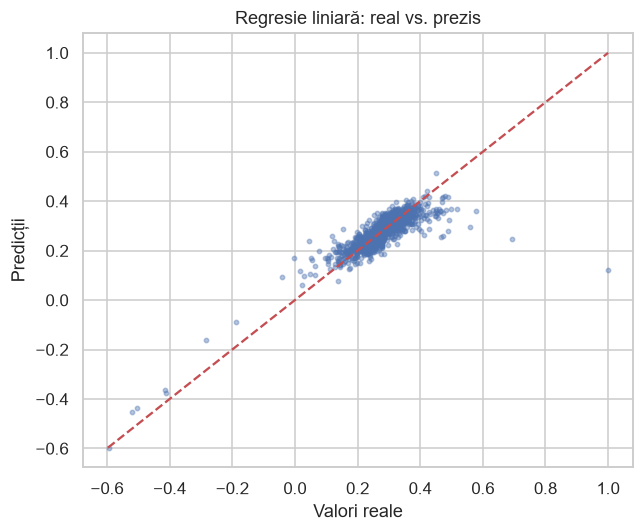

In [5]:
# 5.1 Regresia liniară: modelul antrenat în secțiunea 3.
display(pd.Series(reg_metrics, name='Test').to_frame())
plt.figure(figsize=(6, 5)); plt.scatter(yr_test, reg_pred, s=8, alpha=.4)
lims = [min(yr_test.min(), reg_pred.min()), max(yr_test.max(), reg_pred.max())]
plt.plot(lims, lims, 'r--'); plt.xlabel('Valori reale'); plt.ylabel('Predicții')
plt.title('Regresie liniară: real vs. prezis'); plt.tight_layout(); plt.show()


In [6]:
# 5.2 Clasificare binară: activitate dinamică (1) vs. statică (0).
dynamic = ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS']
yb_train = y_train.isin(dynamic).astype(int)
yb_test = y_test.isin(dynamic).astype(int)
binary_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=SEED))
binary_model.fit(X_train, yb_train)
binary_pred = binary_model.predict(X_test)
print(f'Acuratețe logistică binară: {accuracy_score(yb_test, binary_pred):.4f}')
print(classification_report(yb_test, binary_pred, target_names=['statică', 'dinamică']))


Acuratețe logistică binară: 0.9995
              precision    recall  f1-score   support

     statică       1.00      1.00      1.00      1126
    dinamică       1.00      1.00      1.00       934

    accuracy                           1.00      2060
   macro avg       1.00      1.00      1.00      2060
weighted avg       1.00      1.00      1.00      2060



In [7]:
from sklearn.svm import SVC
# 5.3 SVM: clasificarea celor șase activități.
svm_model = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=10))
svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)
print(f'Acuratețe SVM: {accuracy_score(y_test, svm_pred):.4f}')
print(classification_report(y_test, svm_pred))


Acuratețe SVM: 0.9922
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       389
           SITTING       0.97      0.98      0.98       356
          STANDING       0.99      0.97      0.98       381
           WALKING       1.00      1.00      1.00       344
WALKING_DOWNSTAIRS       1.00      1.00      1.00       281
  WALKING_UPSTAIRS       1.00      1.00      1.00       309

          accuracy                           0.99      2060
         macro avg       0.99      0.99      0.99      2060
      weighted avg       0.99      0.99      0.99      2060



In [8]:
# Toate modelele folosesc random_state=42 unde este aplicabil, pentru reproductibilitate.


In [9]:
# Setul de test nu este folosit pentru ajustarea parametrilor sau antrenare.


## 6. Matricea de confuzie
1. Construiește un model de clasificare logistică.
2. Creează matricea de confuzie și afișează-o grafic utilizând Seaborn.

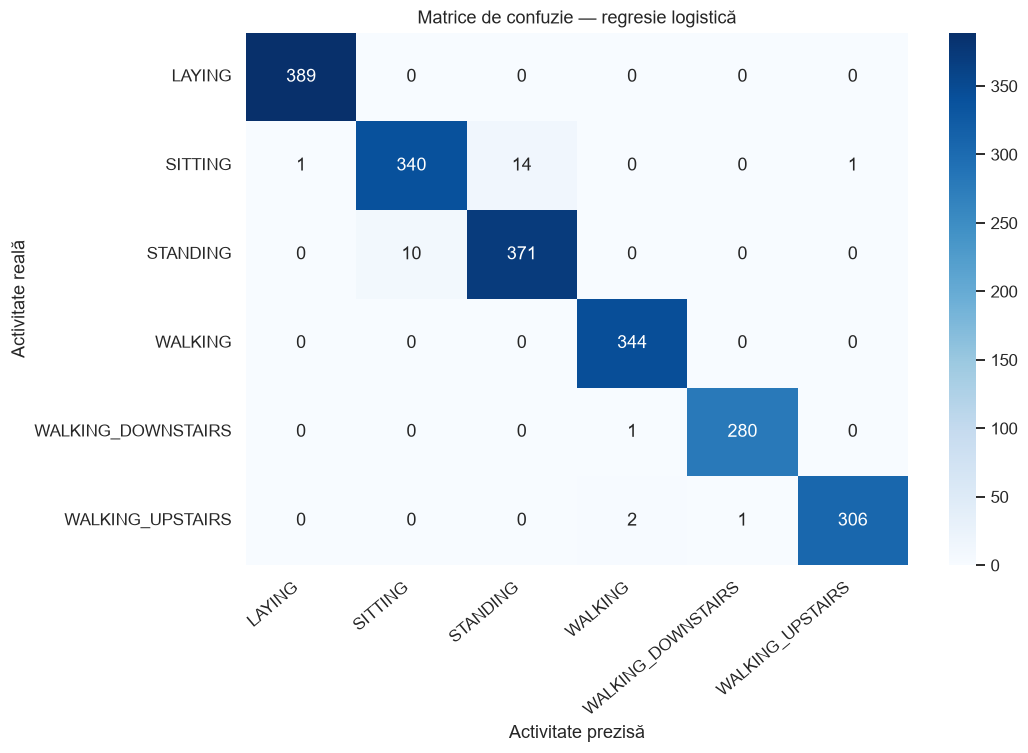

Acuratețe logistică multiclasa: 0.9854
                    precision    recall  f1-score   support

            LAYING       1.00      1.00      1.00       389
           SITTING       0.97      0.96      0.96       356
          STANDING       0.96      0.97      0.97       381
           WALKING       0.99      1.00      1.00       344
WALKING_DOWNSTAIRS       1.00      1.00      1.00       281
  WALKING_UPSTAIRS       1.00      0.99      0.99       309

          accuracy                           0.99      2060
         macro avg       0.99      0.99      0.99      2060
      weighted avg       0.99      0.99      0.99      2060



In [10]:
from sklearn.metrics import confusion_matrix
logistic_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=SEED))
logistic_model.fit(X_train, y_train)
logistic_pred = logistic_model.predict(X_test)
classes = logistic_model.classes_
cm = confusion_matrix(y_test, logistic_pred, labels=classes)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Activitate prezisă'); plt.ylabel('Activitate reală')
plt.title('Matrice de confuzie — regresie logistică'); plt.xticks(rotation=40, ha='right')
plt.tight_layout(); plt.show()
print(f'Acuratețe logistică multiclasa: {accuracy_score(y_test, logistic_pred):.4f}')
print(classification_report(y_test, logistic_pred))



## 7. Gradient Descent
1. Implementați manual algoritmul Gradient Descent pentru a optimiza o funcție cost definită.
2. Utilizați o funcție simplă $$J(\theta) = (\theta x - y)^2 $$ pe un subset al datelor.

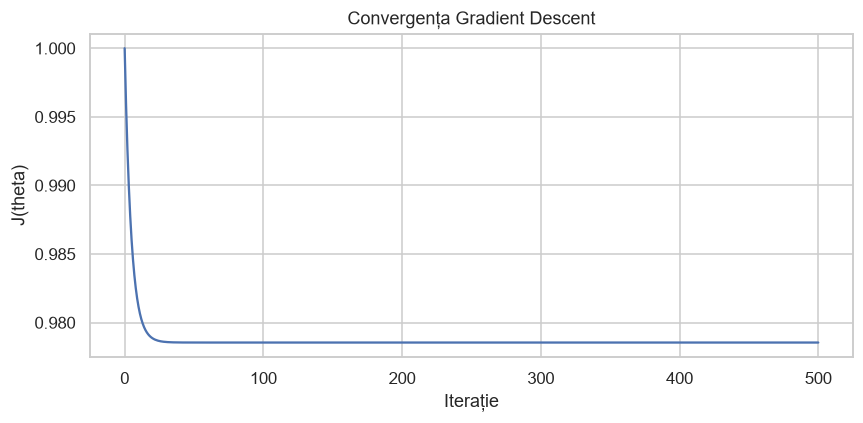

Cost inițial: 1.000000; cost final: 0.978544
Theta GD: -0.146479; soluția analitică: -0.146479


In [11]:
# J(theta) = media((theta*x - y)^2), fără intercept.
# Folosim un subset din train și standardizăm cele două variabile.
x_gd = Xr_train.iloc[:500, 0].to_numpy(dtype=float)
y_gd = yr_train.iloc[:500].to_numpy(dtype=float)
x_gd = (x_gd - x_gd.mean()) / x_gd.std()
y_gd = (y_gd - y_gd.mean()) / y_gd.std()
theta, learning_rate, n_iter = 0., .05, 500
costs = [np.mean((theta*x_gd-y_gd)**2)]
for step in range(n_iter):
    gradient = 2 * np.mean(x_gd * (theta*x_gd-y_gd))
    theta -= learning_rate * gradient
    costs.append(np.mean((theta*x_gd-y_gd)**2))
theta_exact = np.dot(x_gd, y_gd) / np.dot(x_gd, x_gd)
print(f'Cost inițial: {costs[0]:.6f}; cost final: {costs[-1]:.6f}')
print(f'Theta GD: {theta:.6f}; soluția analitică: {theta_exact:.6f}')
assert np.isclose(theta, theta_exact, atol=1e-6)
plt.figure(figsize=(8, 4)); plt.plot(costs)
plt.xlabel('Iterație'); plt.ylabel('J(theta)'); plt.title('Convergența Gradient Descent')
plt.tight_layout(); plt.show()


## 8. Modele de Machine Learning (part 2 - poate fi omis)
1. **Random Forest**: Utilizează Random Forest pentru a antrena un model și evaluează importanța caracteristicilor.
2. **Boosting și Bagging**: Compară performanța dintre un model AdaBoost și un model Bagging.


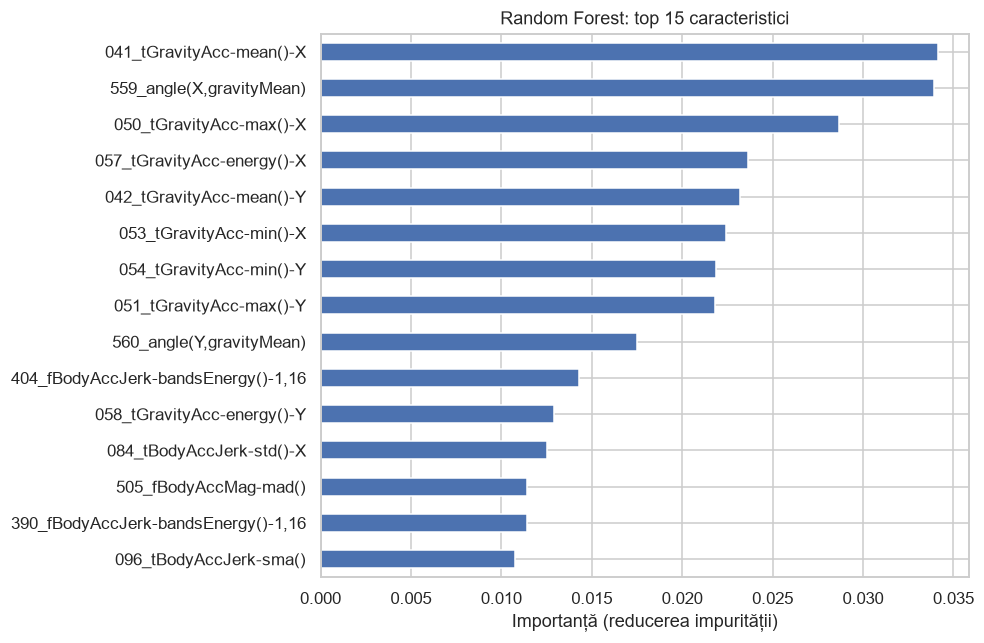

,Acuratețe test
Random Forest,0.981553
AdaBoost,0.904369
Bagging,0.966505


Comparația folosește aceleași date de test și parametrii declarați; nu reprezintă o căutare exhaustivă a parametrilor.


In [12]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
rf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1)
rf.fit(X_train, y_train)
importance = pd.Series(rf.feature_importances_, index=feature_cols).nlargest(15)
plt.figure(figsize=(9, 6)); importance.sort_values().plot.barh()
plt.xlabel('Importanță (reducerea impurității)'); plt.title('Random Forest: top 15 caracteristici')
plt.tight_layout(); plt.show()
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2), n_estimators=60, random_state=SEED)
bag = BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=40, random_state=SEED, n_jobs=1)
ada.fit(X_train, y_train); bag.fit(X_train, y_train)
ensemble_scores = {name: model.score(X_test, y_test) for name, model in [('Random Forest', rf), ('AdaBoost', ada), ('Bagging', bag)]}
display(pd.Series(ensemble_scores, name='Acuratețe test').to_frame())
print('Comparația folosește aceleași date de test și parametrii declarați; nu reprezintă o căutare exhaustivă a parametrilor.')



## 9. Stacking
1. Construiește un model de tip Stacking utilizând Random Forest, SVM și Logistic Regression ca modele de bază.
2. Utilizează un model Logistic Regression ca meta-model.
3. Afișează acuratețea finală pe setul de testare.

In [13]:
from sklearn.ensemble import StackingClassifier
stack = StackingClassifier(
    estimators=[
        ('rf', RandomForestClassifier(n_estimators=80, random_state=SEED, n_jobs=1)),
        ('svm', make_pipeline(StandardScaler(), SVC(C=10, kernel='rbf'))),
        ('lr', make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, random_state=SEED)))],
    final_estimator=LogisticRegression(max_iter=3000, random_state=SEED),
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED), n_jobs=1)
# Meta-modelul se antrenează pe predicții out-of-fold, nu pe predicții din test.
stack.fit(X_train, y_train)
stack_pred = stack.predict(X_test)
print(f'Acuratețe finală Stacking: {accuracy_score(y_test, stack_pred):.4f}')
results = {'KNN': knn.score(X_test, y_test), 'Logistică': accuracy_score(y_test, logistic_pred),
           'SVM': accuracy_score(y_test, svm_pred), **ensemble_scores,
           'Stacking': accuracy_score(y_test, stack_pred)}
display(pd.Series(results, name='Acuratețe test').sort_values(ascending=False).to_frame())
print('Concluzie: acuratețile compară clasificatoare pe aceeași împărțire 80/20. '
      'Metricile de regresie se referă separat la o măsurătoare numerică. '
      'Pentru evaluare pe persoane nevăzute este necesară o împărțire pe Subject.')


,Acuratețe test
Stacking,0.993204
SVM,0.992233
Logistică,0.985437
Random Forest,0.981553
KNN,0.967961
Bagging,0.966505
AdaBoost,0.904369


Acuratețe finală Stacking: 0.9932
Concluzie: acuratețile compară clasificatoare pe aceeași împărțire 80/20. Metricile de regresie se referă separat la o măsurătoare numerică. Pentru evaluare pe persoane nevăzute este necesară o împărțire pe Subject.



## Observații
Te rog, să salvezi  și să predai acest notebook după ce ai completat toate secțiunile.
